In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
import matplotlib.dates as mdates
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("ambient_temperature_system_failure.csv")

In [3]:
df = df.rename(columns={'timestamp':'Time','value':'Temp'})
df.head()

,Time,Temp
0,2013-07-04 00:00:00,69.880835
1,2013-07-04 01:00:00,71.220227
2,2013-07-04 02:00:00,70.877805
3,2013-07-04 03:00:00,68.959400
4,2013-07-04 04:00:00,69.283551


In [4]:
df['Time'] = pd.to_datetime(df['Time'])

### Original Dataset(Temp vs time)

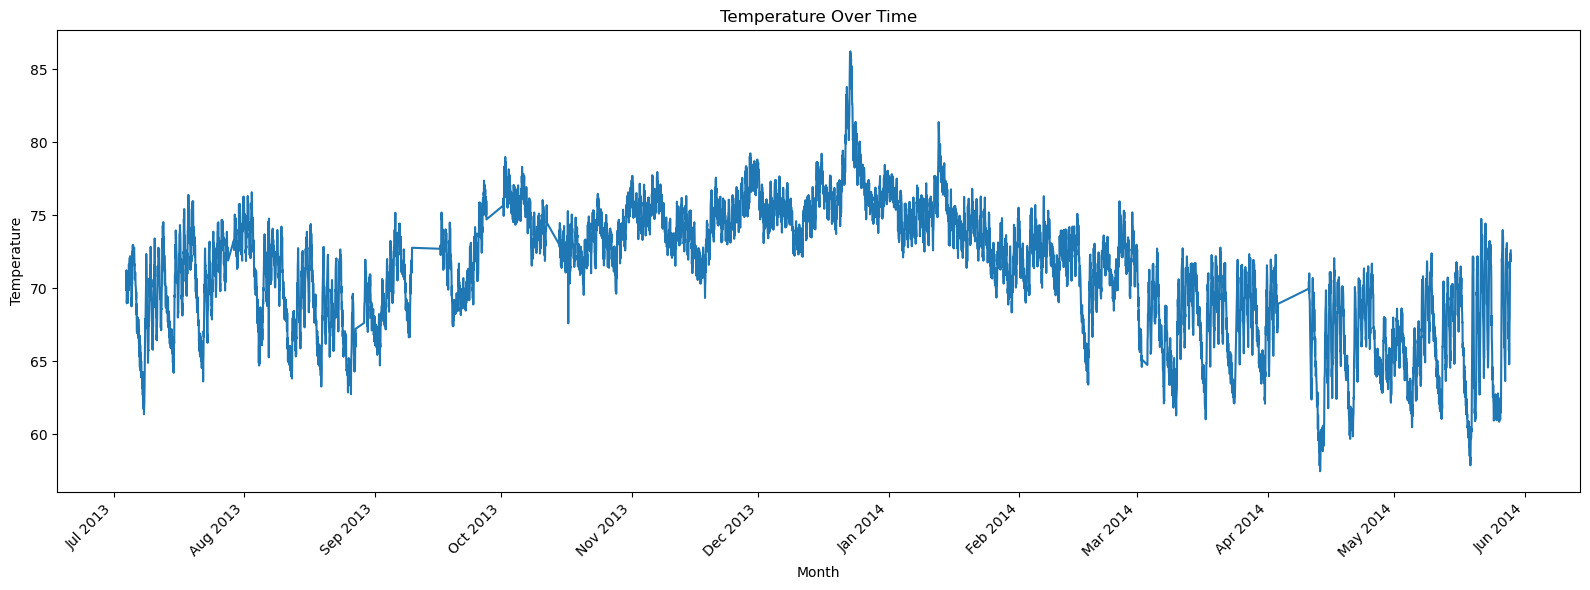

In [5]:
plt.figure(figsize=(16, 6))
plt.plot(df['Time'], df['Temp'])

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xlabel('Month')
plt.ylabel('Temperature')
plt.title('Temperature Over Time')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [6]:
X = df[['Temp']]

In [7]:
scaler = StandardScaler()
X_z_score = scaler.fit_transform(X)

In [8]:
df['X_z_score'] = X_z_score.flatten() #.flatten converts high dimensional array to low dimensional(2d to 1d here)

### Z_score value vs Time

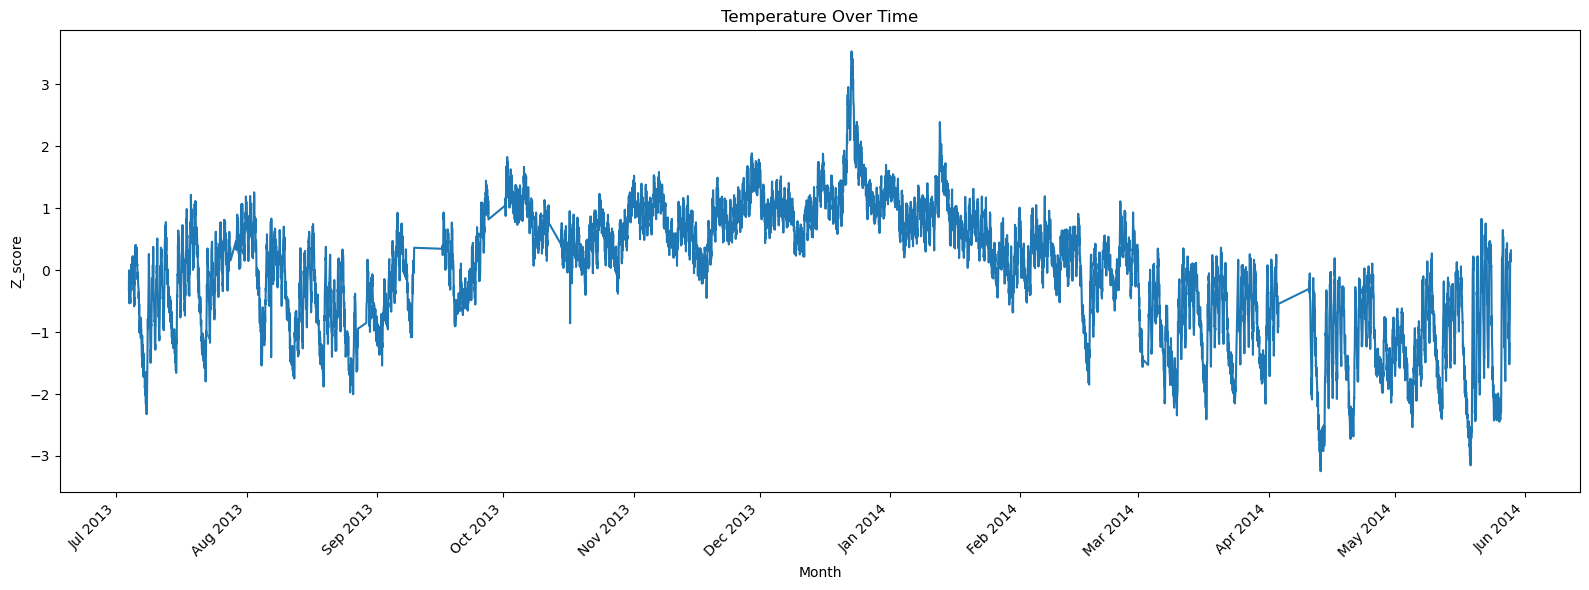

In [9]:
plt.figure(figsize=(16, 6))
plt.plot(df['Time'], df['X_z_score'])

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xlabel('Month')
plt.ylabel('Z_score')
plt.title('Temperature Over Time')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [10]:
scaler = MinMaxScaler()
X_min_max = scaler.fit_transform(X)

In [11]:
df['X_min_max'] = X_min_max.flatten()

### Min_max Scaling

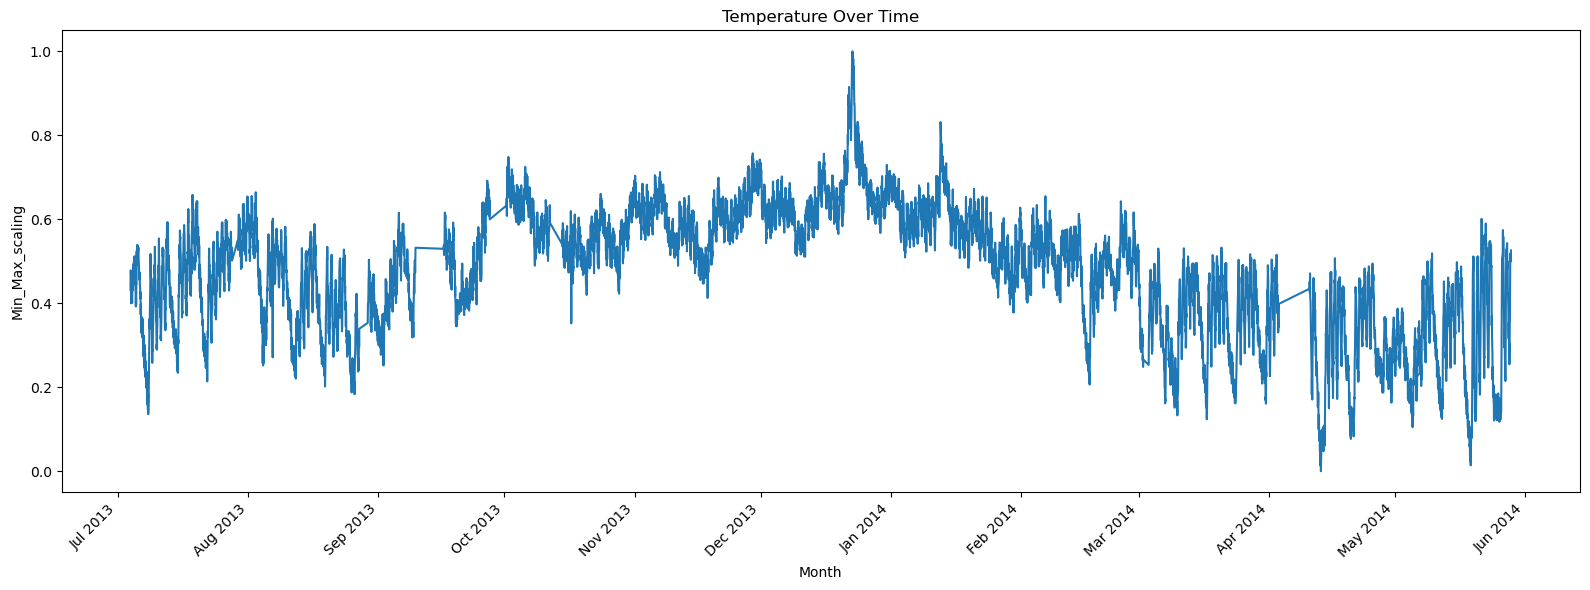

In [12]:
plt.figure(figsize=(16, 6))
plt.plot(df['Time'], df['X_min_max'])

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xlabel('Month')
plt.ylabel('Min_Max_scaling')
plt.title('Temperature Over Time')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [13]:
df["rolling_mean"] = (
    df["Temp"].shift(1).rolling(window=3).mean()
)

df["rolling_std"] = (
    df["Temp"].shift(1).rolling(window=3).std()
)

### Rolling mean

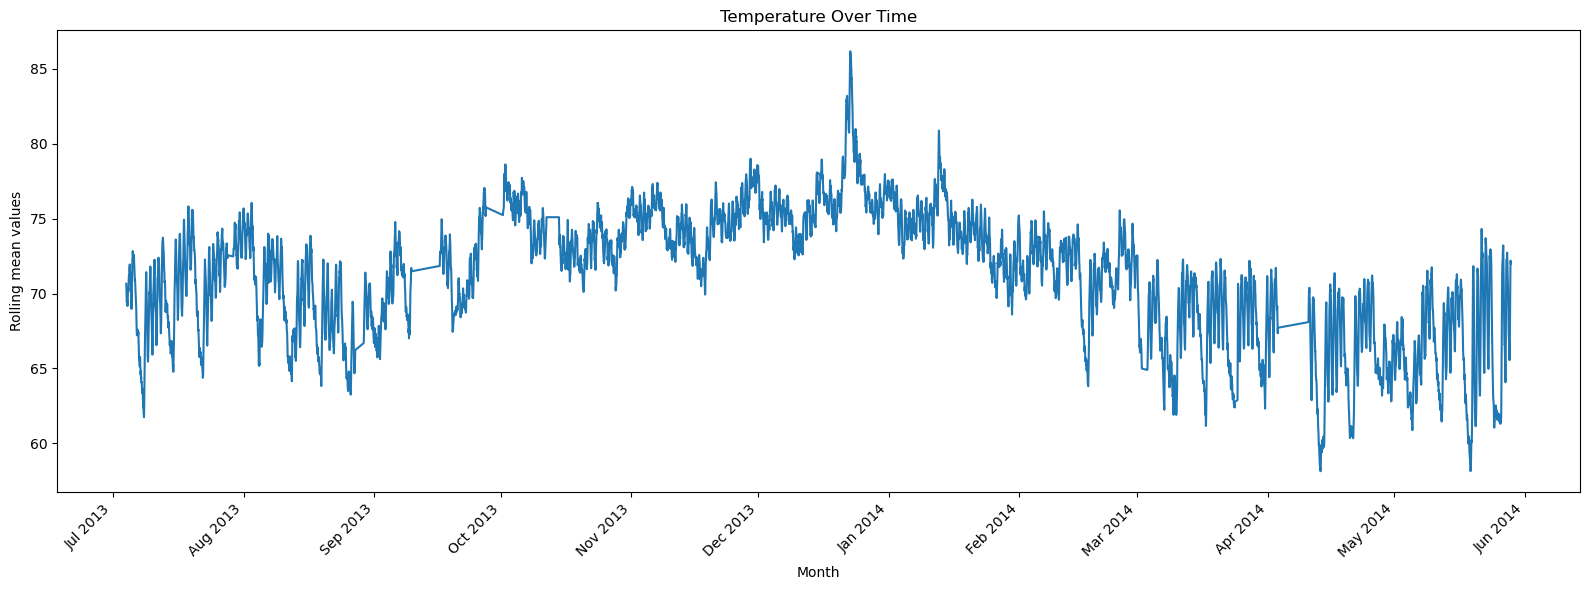

In [14]:
plt.figure(figsize=(16, 6))
plt.plot(df['Time'], df['rolling_mean'])

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xlabel('Month')
plt.ylabel('Rolling mean values')
plt.title('Temperature Over Time')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Rolling Standard Deviation

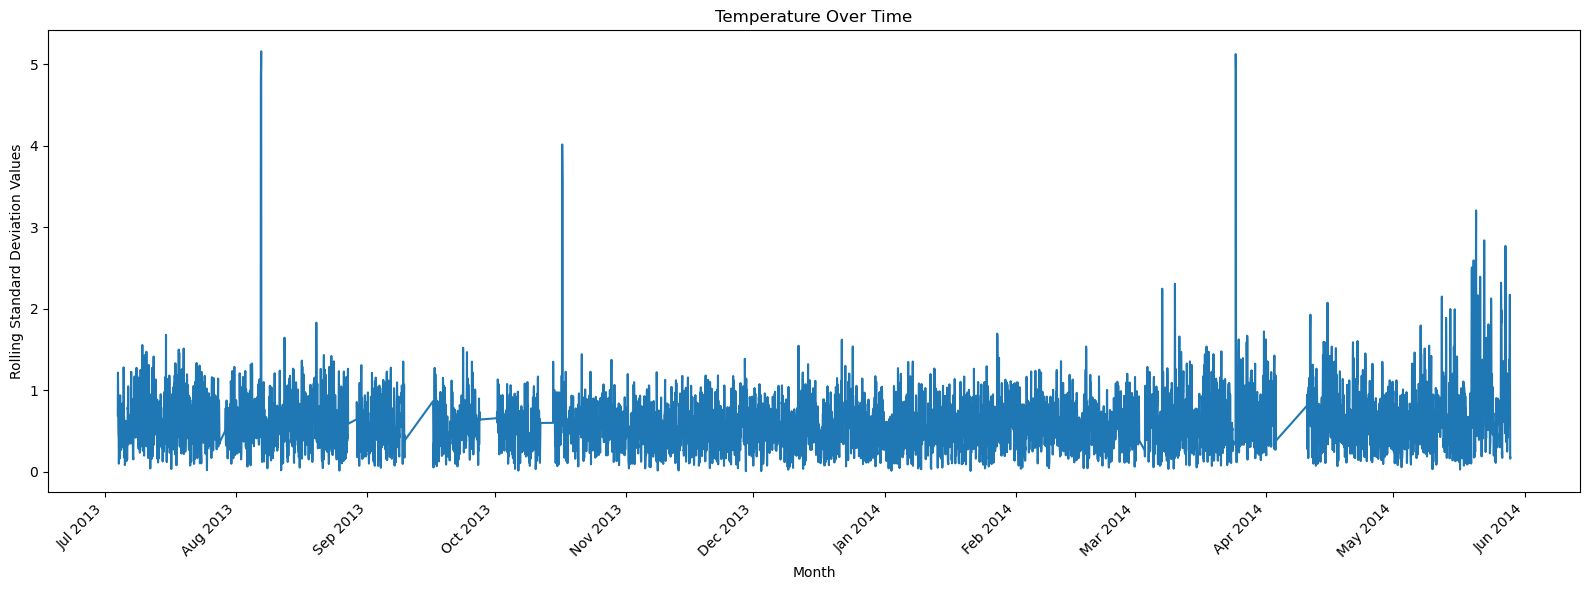

In [15]:
plt.figure(figsize=(16, 6))
plt.plot(df['Time'], df['rolling_std'])

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xlabel('Month')
plt.ylabel('Rolling Standard Deviation Values')
plt.title('Temperature Over Time')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [16]:
df["lag_1"] = df["Temp"].shift(30*24)

### Lag features(shifting by one month)

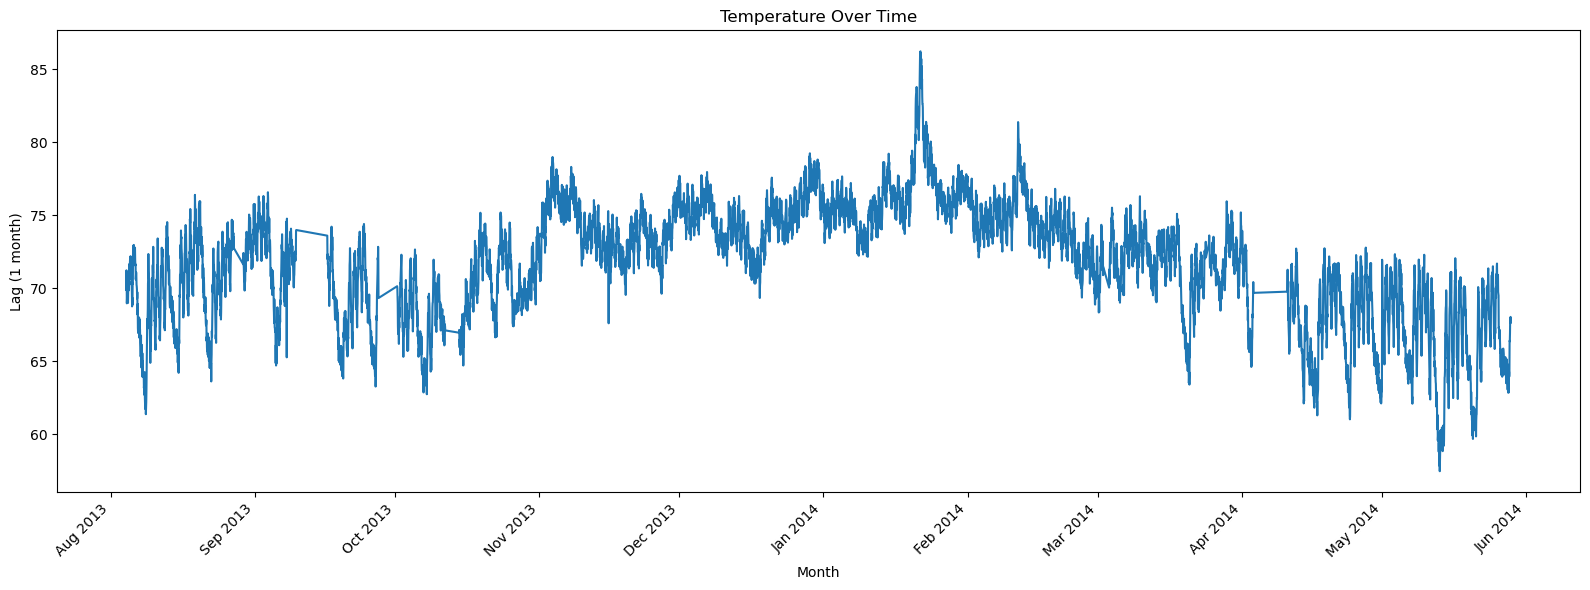

In [17]:
plt.figure(figsize=(16, 6))
plt.plot(df['Time'], df['lag_1'])

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xlabel('Month')
plt.ylabel('Lag (1 month)')
plt.title('Temperature Over Time')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [18]:
df["Diffrence"] = df["Temp"].diff() #Xt = Xt - Xt-1

df["rate_of_change"] = (
    df["Temp"].pct_change() * 100
)

### Diffrence over every timestamp

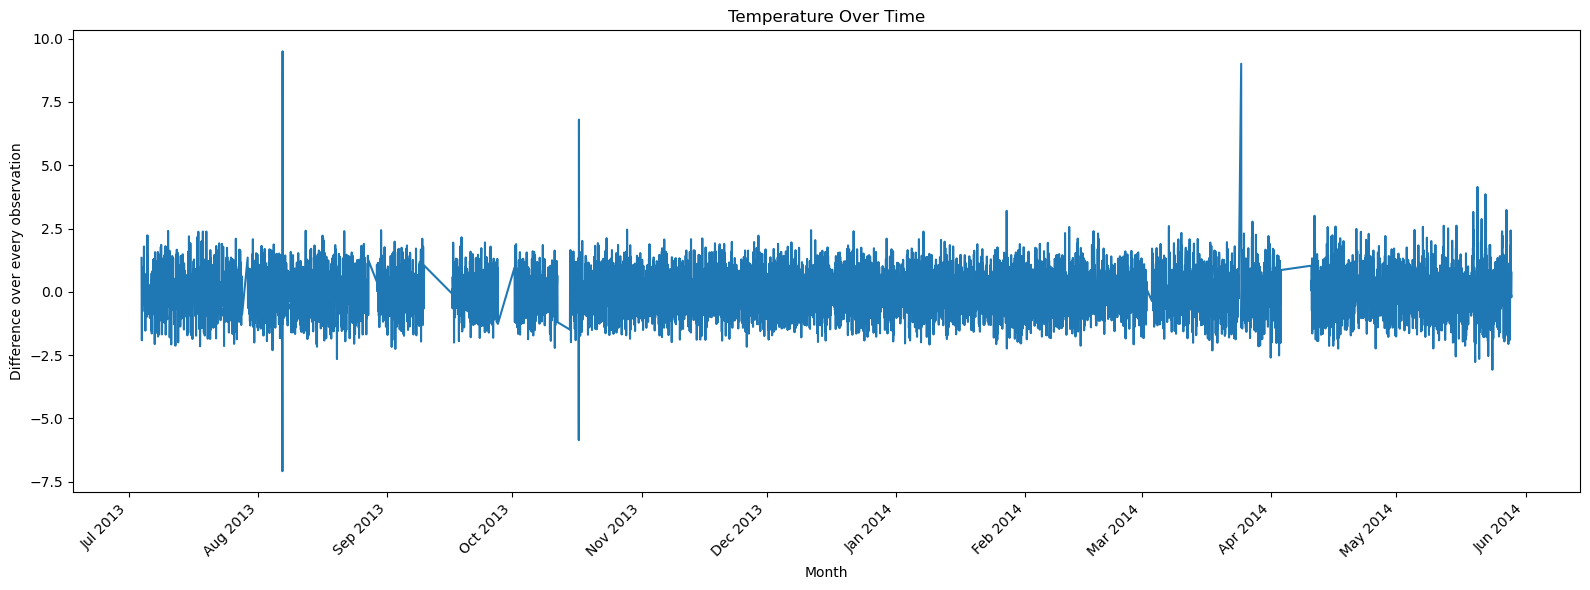

In [19]:
plt.figure(figsize=(16, 6))
plt.plot(df['Time'], df['Diffrence'])

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xlabel('Month')
plt.ylabel('Difference over every observation')
plt.title('Temperature Over Time')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Rate of Chnage over time

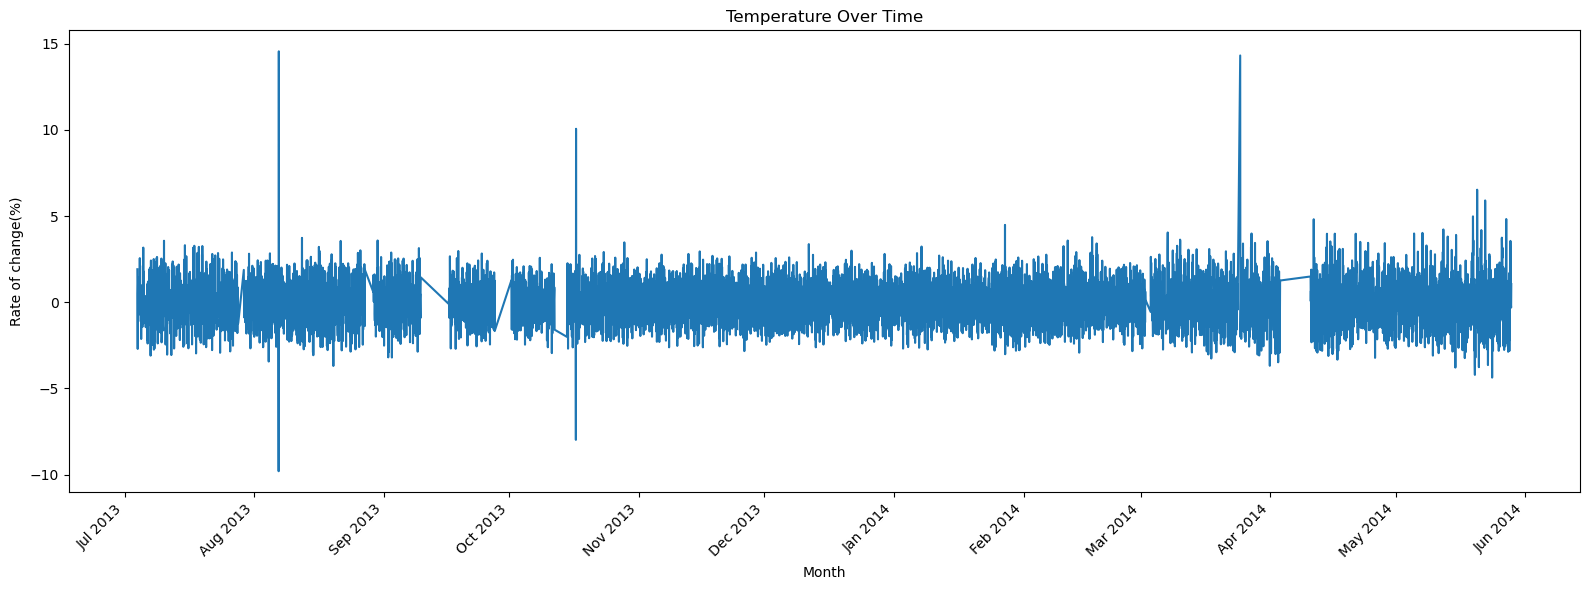

In [20]:
plt.figure(figsize=(16, 6))
plt.plot(df['Time'], df['rate_of_change'])

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xlabel('Month')
plt.ylabel('Rate of change(%)')
plt.title('Temperature Over Time')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [21]:
df.head(20)

,Time,Temp,X_z_score,X_min_max,rolling_mean,rolling_std,lag_1,Diffrence,rate_of_change
0,2013-07-04 00:00:00,69.880835,-0.320586,0.431862,NaN,NaN,NaN,NaN,NaN
1,2013-07-04 01:00:00,71.220227,-0.005228,0.478426,NaN,NaN,NaN,1.339392,1.916680
2,2013-07-04 02:00:00,70.877805,-0.085851,0.466521,NaN,NaN,NaN,-0.342422,-0.480793
3,2013-07-04 03:00:00,68.959400,-0.537536,0.399829,70.659622,0.695842,NaN,-1.918405,-2.706637
4,2013-07-04 04:00:00,69.283551,-0.461215,0.411098,70.352477,1.218528,NaN,0.324151,0.470061
5,2013-07-04 05:00:00,70.060966,-0.278174,0.438124,69.706919,1.026888,NaN,0.777415,1.122077
6,2013-07-04 06:00:00,69.279765,-0.462107,0.410966,69.434639,0.566112,NaN,-0.781201,-1.115030
7,2013-07-04 07:00:00,69.369608,-0.440953,0.414089,69.541427,0.449938,NaN,0.089844,0.129682
8,2013-07-04 08:00:00,69.166714,-0.488724,0.407036,69.570113,0.427458,NaN,-0.202895,-0.292483
9,2013-07-04 09:00:00,68.986083,-0.531254,0.400756,69.272029,0.101668,NaN,-0.180631,-0.261154


In [22]:
df_train = df[['Time','Temp','X_z_score','rolling_std','rate_of_change']]
df_train.head()

,Time,Temp,X_z_score,rolling_std,rate_of_change
0,2013-07-04 00:00:00,69.880835,-0.320586,NaN,NaN
1,2013-07-04 01:00:00,71.220227,-0.005228,NaN,1.916680
2,2013-07-04 02:00:00,70.877805,-0.085851,NaN,-0.480793
3,2013-07-04 03:00:00,68.959400,-0.537536,0.695842,-2.706637
4,2013-07-04 04:00:00,69.283551,-0.461215,1.218528,0.470061


In [23]:
df_train['Time'] = pd.to_datetime(df_train['Time'])

df_train['hour'] = df_train['Time'].dt.hour
df_train['day'] = df_train['Time'].dt.day
df_train['month'] = df_train['Time'].dt.month

df_train = df_train.drop(columns=['Time'])

df_train = df_train.replace([np.inf, -np.inf], np.nan)

C:\Users\vishrutv\AppData\Local\Temp\ipykernel_22620\1966441347.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train['Time'] = pd.to_datetime(df_train['Time'])
C:\Users\vishrutv\AppData\Local\Temp\ipykernel_22620\1966441347.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train['hour'] = df_train['Time'].dt.hour
C:\Users\vishrutv\AppData\Local\Temp\ipykernel_22620\1966441347.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_ind

In [24]:
features = ['X_z_score','rolling_std', 'rate_of_change', 'hour', 'day', 'month']

X = df_train[features]
y = df_train['Temp']

In [25]:
X

,X_z_score,rolling_std,rate_of_change,hour,day,month
0,-0.320586,NaN,NaN,0,4,7
1,-0.005228,NaN,1.916680,1,4,7
2,-0.085851,NaN,-0.480793,2,4,7
3,-0.537536,0.695842,-2.706637,3,4,7
4,-0.461215,1.218528,0.470061,4,4,7
...,...,...,...,...,...,...
7262,0.265532,1.585482,2.717295,11,28,5
7263,0.219090,2.173519,-0.272557,12,28,5
7264,0.189332,1.053019,-0.175122,13,28,5
7265,0.137218,0.163108,-0.307217,14,28,5


In [26]:
y

0       69.880835
1       71.220227
2       70.877805
3       68.959400
4       69.283551
          ...    
7262    72.370206
7263    72.172956
7264    72.046565
7265    71.825226
7266    72.584089
Name: Temp, Length: 7267, dtype: float64

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2,shuffle=False)

In [28]:
print(X_train.head())
print()
print(X_test.head())

   X_z_score  rolling_std  rate_of_change  hour  day  month
0  -0.320586          NaN             NaN     0    4      7
1  -0.005228          NaN        1.916680     1    4      7
2  -0.085851          NaN       -0.480793     2    4      7
3  -0.537536     0.695842       -2.706637     3    4      7
4  -0.461215     1.218528        0.470061     4    4      7

      X_z_score  rolling_std  rate_of_change  hour  day  month
5813  -1.191362     0.795691       -0.237930     7   21      3
5814  -1.172196     0.089510        0.122994     8   21      3
5815  -0.710720     0.078935        2.957855     9   21      3
5816  -0.489298     1.155815        1.378446    10   21      3
5817  -0.502242     1.479774       -0.079488    11   21      3


In [29]:
print(y_train.head())
print()
print(y_test.head())

0    69.880835
1    71.220227
2    70.877805
3    68.959400
4    69.283551
Name: Temp, dtype: float64

5813    66.182459
5814    66.263860
5815    68.223849
5816    69.164278
5817    69.109300
Name: Temp, dtype: float64


### Using Random Forest Regressor for temperature prediction

In [30]:
model = RandomForestRegressor(
    n_estimators=500,
    max_depth=5,
    bootstrap=True, 
    max_samples=0.8,
    =0.8,
    objective='reg:squarederror',
    random_state=42,
)

TypeError: RandomForestRegressor.__init__() got an unexpected keyword argument 'subsample'

In [79]:
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 0.27017782784057454
RMSE: 0.6148435025633544
R2 Score: 0.9665122234183279


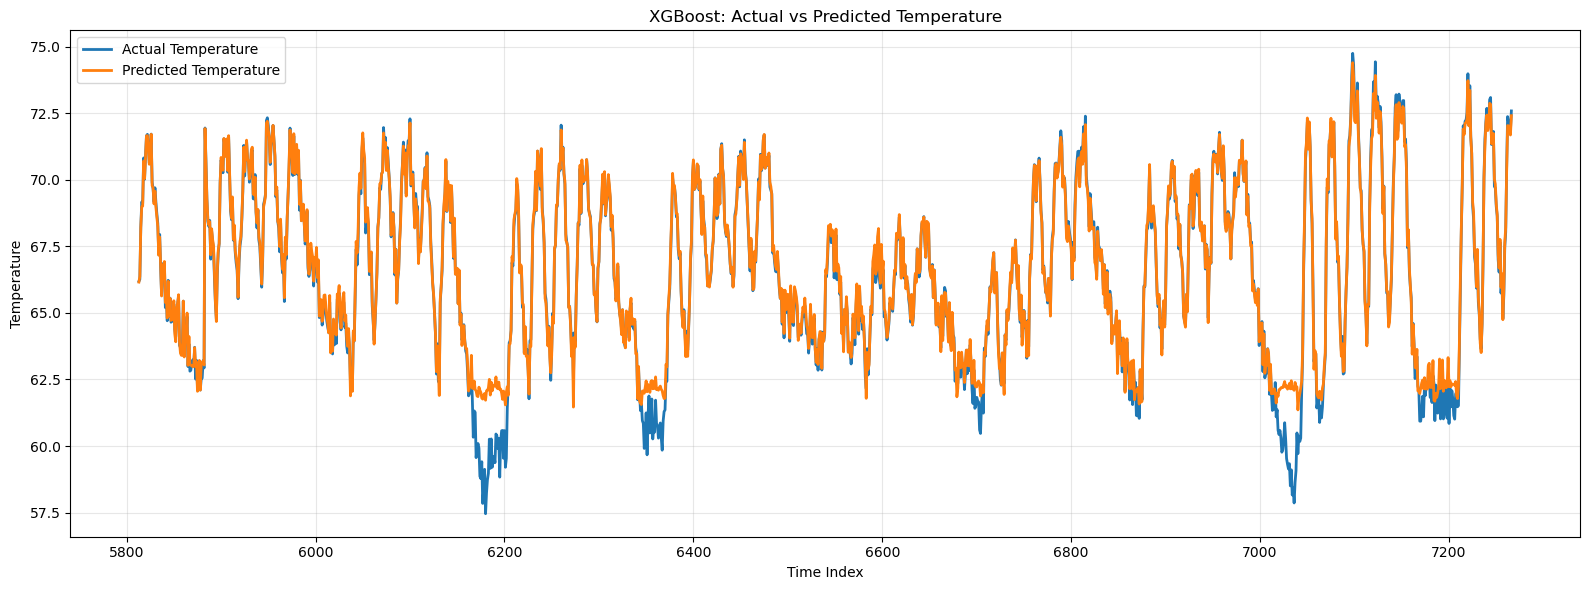

In [88]:
plt.figure(figsize=(16, 6))

plt.plot(y_test.index, y_test, label='Actual Temperature', linewidth=2)
plt.plot(y_test.index, y_pred, label='Predicted Temperature', linewidth=2)

plt.xlabel('Time Index')
plt.ylabel('Temperature')
plt.title('XGBoost: Actual vs Predicted Temperature')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [86]:
len(y_test),len(y_pred)

(1454, 1454)

In [90]:
y_test_plot = y_test[1347:]
y_pred_plot = y_pred[1347:]

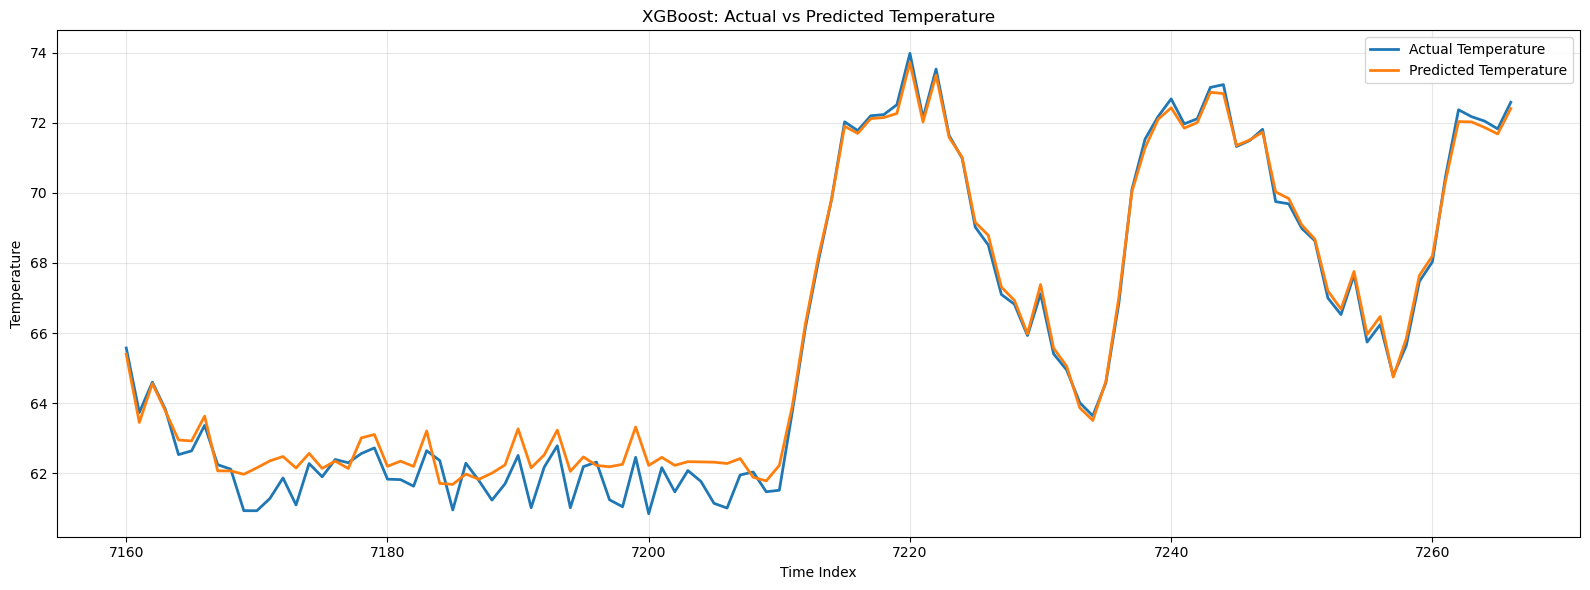

In [91]:
plt.figure(figsize=(16, 6))

plt.plot(y_test_plot.index, y_test_plot, label='Actual Temperature', linewidth=2)
plt.plot(y_test_plot.index, y_pred_plot, label='Predicted Temperature', linewidth=2)

plt.xlabel('Time Index')
plt.ylabel('Temperature')
plt.title('XGBoost: Actual vs Predicted Temperature')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()